# P14. Квантованные функции активации

**Вопрос:** что даёт квантование не только весов, но и *значений активаций*?
**Метрики:** ошибка аппроксимации · точность · скорость · устойчивость.
Данные: `digits` (offline), **все вычисления в float32**, seed фиксированы.

Активацию огрубляем двумя способами — **(a)** квантуем *выходное значение* активации на $2^b$ уровней;
**(b)** заменяем саму функцию *таблицей (LUT) / кусочно-линейной (PWL)* аппроксимацией по входу.
Квантователи имеют сигнатуру `q(z, ex)`: `z` — вход активации, `ex` — точное `f(z)`; способ (a) огрубляет
`ex`, способ (b) отображает `z` через таблицу. *Замечание:* в LUT адрес узла b-битный, но сами значения
узлов хранятся во float — это аппроксимация функции, а не b-битное хранение активации.

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED=42; rng=np.random.default_rng(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi":80,"font.size":10,"axes.grid":True,"grid.alpha":0.3})
PAL=["#2563eb","#dc2626","#16a34a","#ea580c","#7c3aed"]
F32=np.float32

digits=load_digits()
X=(digits.data.astype(F32)/F32(16.0))            # пиксели 0..16 -> [0,1], float32
y=digits.target.astype(np.int64)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=SEED,stratify=y)
onehot=lambda y,k=10: np.eye(k,dtype=F32)[y]
Ytr,Yte=onehot(ytr),onehot(yte)
print("train",Xtr.shape,"test",Xte.shape,"| dtype X:",X.dtype)

train (1347, 64) test (450, 64) | dtype X: float32


## 1. Активации, квантователи, ошибка аппроксимации

In [ ]:
def act_forward(name, x):
    return {"tanh": np.tanh(x), "sigmoid": 1/(1+np.exp(-x))}[name]
def act_deriv(name, x):
    if name=="tanh": t=np.tanh(x); return 1-t*t
    s=1/(1+np.exp(-x)); return s*(1-s)
def act_range(name):
    return {"tanh": (-1.0, 1.0), "sigmoid": (0.0, 1.0)}[name]

# (a) равномерное квантование ВЫХОДНОГО значения активации на 2**bits уровней в [lo,hi]
def quant_uniform_value(a, lo, hi, bits):
    if bits is None: return a
    levels=2**bits; ac=np.clip(a,lo,hi); step=(hi-lo)/(levels-1)
    return (np.round((ac-lo)/step)*step+lo).astype(a.dtype)

# (b) таблица (LUT) по ВХОДУ: nodes узлов на [-R,R]; нечётное nodes => узел 0 включён (tanh(0)=0)
def make_lut(name, R, nodes, interp=False):
    grid=np.linspace(-R,R,nodes).astype(F32); vals=act_forward(name,grid).astype(F32)
    def f(x):
        xc=np.clip(x,-R,R)
        if interp: return np.interp(xc,grid,vals).astype(x.dtype)          # линейно между узлами
        return vals[np.round((xc+R)/(2*R)*(nodes-1)).astype(int)]           # ближайший узел
    return f, grid, vals

# кусочно-линейная аппроксимация: segs отрезков (segs+1 узлов) на [-R,R]
def make_pwl(name, R, segs):
    knots=np.linspace(-R,R,segs+1).astype(F32); kvals=act_forward(name,knots).astype(F32)
    return (lambda x: np.interp(np.clip(x,-R,R),knots,kvals).astype(x.dtype)), knots, kvals

**Таблица значений активации** (LUT `tanh`, 9 узлов — узел 0 включён, поэтому `tanh(0)=0` точно):

In [ ]:
_, grid9, vals9 = make_lut("tanh", 4.0, 9)
pd.DataFrame({"вход z (узел)": grid9, "tanh(z) точное": act_forward("tanh",grid9),
              "значение в таблице": vals9}).round(4)

,вход z (узел),tanh(z) точное,значение в таблице
0,-4.0,-0.9993,-0.9993
1,-3.0,-0.9951,-0.9951
2,-2.0,-0.9640,-0.9640
3,-1.0,-0.7616,-0.7616
4,0.0,0.0000,0.0000
5,1.0,0.7616,0.7616
6,2.0,0.9640,0.9640
7,3.0,0.9951,0.9951
8,4.0,0.9993,0.9993


**Ошибка аппроксимации** (MSE и максимум $|f-\hat f|$ на сетке $z\in[-5,5]$), по числу узлов:

In [ ]:
xg=np.linspace(-5,5,2000).astype(F32); rows=[]
for nodes in [3,5,9,17,33,65]:
    r={"узлы": nodes}
    for name in ["tanh","sigmoid"]:
        t=act_forward(name,xg)
        lut_f,_,_=make_lut(name,4.0,nodes)              # кусочно-постоянная
        pwl_f,_,_=make_pwl(name,4.0,nodes-1)            # PWL с тем же числом узлов
        r[f"{name} LUT-MSE"]=np.mean((lut_f(xg)-t)**2)
        r[f"{name} LUT-max"]=np.max(np.abs(lut_f(xg)-t))
        r[f"{name} PWL-MSE"]=np.mean((pwl_f(xg)-t)**2)
    rows.append(r)
pd.DataFrame(rows).set_index("узлы").style.format("{:.2e}")

,tanh LUT-MSE,tanh LUT-max,tanh PWL-MSE,sigmoid LUT-MSE,sigmoid LUT-max,sigmoid PWL-MSE
узлы,,,,,,
3,2.07e-01,9.64e-01,1.08e-01,2.47e-02,3.81e-01,8.02e-03
5,4.95e-02,7.61e-01,1.61e-02,5.54e-03,2.31e-01,4.51e-04
9,1.11e-02,4.60e-01,8.85e-04,1.39e-03,1.22e-01,3.74e-05
17,2.77e-03,2.43e-01,5.39e-05,3.57e-04,6.16e-02,1.24e-05
33,6.94e-04,1.22e-01,3.48e-06,9.74e-05,3.06e-02,1.08e-05
65,1.73e-04,6.19e-02,2.51e-07,3.24e-05,1.56e-02,1.07e-05


## 2. Модель (MLP tanh, float32). Градиент через квантователь — по STE

In [ ]:
class QMLP:
    def __init__(self, sizes, act="tanh"):
        self.sizes=sizes; self.act=act; self.L=len(sizes)-1; self.W=[]; self.b=[]
        for i in range(self.L):
            scale=F32(np.sqrt((1 if act=="tanh" else 2)/sizes[i]))
            self.W.append((rng.standard_normal((sizes[i],sizes[i+1])).astype(F32))*scale)
            self.b.append(np.zeros(sizes[i+1],dtype=F32))

    def clone(self):                                     # копия с ТЕМИ ЖЕ начальными весами
        m=QMLP(self.sizes,self.act); m.W=[w.copy() for w in self.W]; m.b=[b.copy() for b in self.b]
        return m

    def _wq(self, W, bits):                              # веса: равномерно на 2**bits уровней в [-m,m]
        if bits is None: return W                        # (тот же квантователь, что и для активаций)
        m=F32(np.max(np.abs(W))+1e-12); return quant_uniform_value(W,-m,m,bits)

    def forward(self, X, act_q=None, w_bits=None, cache=False):
        a=X; caches=[]
        for i in range(self.L):
            W=self._wq(self.W[i], w_bits); z=a@W+self.b[i]
            if i<self.L-1:                               # скрытый слой -> активация
                exact=act_forward(self.act,z)
                h=act_q(z,exact) if act_q is not None else exact
            else:                                        # выходной слой -> логиты
                h=z
            if cache: caches.append((a,z,W))
            a=h
        return a, caches

    def loss_grad(self, X, Y, act_q=None, w_bits=None):
        logits,C=self.forward(X,act_q,w_bits,cache=True)
        logits=logits-logits.max(1,keepdims=True)
        p=np.exp(logits); p/=p.sum(1,keepdims=True)
        n=X.shape[0]; gW=[None]*self.L; gb=[None]*self.L; delta=(p-Y)/n
        for i in reversed(range(self.L)):
            a,z,W=C[i]; gW[i]=a.T@delta; gb[i]=delta.sum(0)
            if i>0: delta=(delta@W.T)*act_deriv(self.act,C[i-1][1])   # STE: назад гладкая f'
        return gW, gb

    def input_grad(self, X, Y, act_q=None, w_bits=None, hidden_deriv=None):
        # dL/dX для FGSM. hidden_deriv=None -> STE; можно задать 'истинный' наклон огрублённой
        # активации (0 для кусочно-постоянной LUT) — для демонстрации маскировки градиента.
        logits,C=self.forward(X,act_q,w_bits,cache=True)
        logits=logits-logits.max(1,keepdims=True)
        p=np.exp(logits); p/=p.sum(1,keepdims=True); delta=(p-Y)/X.shape[0]
        for i in reversed(range(self.L)):
            a,z,W=C[i]
            if i>0:
                zprev=C[i-1][1]
                d=act_deriv(self.act,zprev) if hidden_deriv is None else hidden_deriv(zprev)
                delta=(delta@W.T)*d
            else:
                dX=delta@W.T
        return dX

    def predict(self, X, act_q=None, w_bits=None):
        return self.forward(X,act_q,w_bits)[0].argmax(1)

def accuracy(m,X,y,act_q=None,w_bits=None): return float(np.mean(m.predict(X,act_q,w_bits)==y))
def margin(m,X,act_q=None,w_bits=None):                 # запас логитов: top1 - top2
    lg,_=m.forward(X,act_q,w_bits); s=np.sort(lg,1); return float(np.mean(s[:,-1]-s[:,-2]))

def train(m,X,Y,y,epochs=60,bs=64,lr=2e-3,act_q=None,w_bits=None):
    mW=[np.zeros_like(w) for w in m.W]; vW=[np.zeros_like(w) for w in m.W]
    mb=[np.zeros_like(b) for b in m.b]; vb=[np.zeros_like(b) for b in m.b]
    b1,b2,e=0.9,0.999,1e-8; t=0; n=X.shape[0]
    for _ in range(epochs):
        idx=rng.permutation(n)
        for st in range(0,n,bs):
            bi=idx[st:st+bs]; t+=1; gW,gb=m.loss_grad(X[bi],Y[bi],act_q,w_bits)
            for i in range(m.L):
                mW[i]=b1*mW[i]+(1-b1)*gW[i]; vW[i]=b2*vW[i]+(1-b2)*gW[i]**2
                mb[i]=b1*mb[i]+(1-b1)*gb[i]; vb[i]=b2*vb[i]+(1-b2)*gb[i]**2
                m.W[i]-=lr*(mW[i]/(1-b1**t))/(np.sqrt(vW[i]/(1-b2**t))+e)
                m.b[i]-=lr*(mb[i]/(1-b1**t))/(np.sqrt(vb[i]/(1-b2**t))+e)
    return m

init=QMLP([64,128,64,10],"tanh")            # общая начальная инициализация (для честного QAT)
base=init.clone(); train(base,Xtr,Ytr,ytr,60)
BASE=accuracy(base,Xte,yte)
print(f"fp32 base: acc={BASE:.4f} | dtype логитов: {base.forward(Xte)[0].dtype}")

ACT="tanh"; LO,HI=act_range(ACT); R=4.0
q_value=lambda b:  (lambda z,ex: quant_uniform_value(ex,LO,HI,b))   # (a) огрубляем выход ex
q_lut  =lambda nd: (lambda z,ex: make_lut(ACT,R,nd)[0](z))          # (b) вход z через таблицу (nd узлов)
q_pwl  =lambda sg: (lambda z,ex: make_pwl(ACT,R,sg)[0](z))          # (b) кусочно-линейная

fp32 base: acc=0.9711 | dtype логитов: float32


## 3. PTQ активаций: точность, запас логитов и расхождение с fp32

Точность на тесте (450 объектов) шумит на уровне ±0.2%/объект, поэтому при 3–8 битах колеблется
вокруг fp32 без тренда. Монотонный эффект квантования видно по **расхождению с fp32** (доля
изменённых ответов, MSE логитов). **Запас логитов** (top1−top2) при 1 бите даже растёт — грубая
активация делает ответы «увереннее», хотя часть из них меняется.

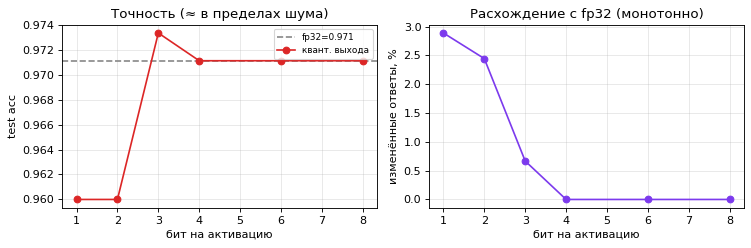

,acc,"изм. ответы,%",MSE логитов,запас логитов
бит,,,,
1,0.960,2.89,1.9175,9.48
2,0.960,2.44,0.6058,7.92
3,0.973,0.67,0.1106,8.13
4,0.971,0.00,0.0250,7.99
6,0.971,0.00,0.0014,7.97
8,0.971,0.00,0.0001,7.96


In [ ]:
ref_logits,_=base.forward(Xte); ref_pred=ref_logits.argmax(1)
bits=[1,2,3,4,6,8]
acc_v =[accuracy(base,Xte,yte,act_q=q_value(b)) for b in bits]
chg   =[np.mean(base.forward(Xte,act_q=q_value(b))[0].argmax(1)!=ref_pred)*100 for b in bits]
lmse  =[float(np.mean((base.forward(Xte,act_q=q_value(b))[0]-ref_logits)**2)) for b in bits]
marg  =[margin(base,Xte,act_q=q_value(b)) for b in bits]

fig,ax=plt.subplots(1,2,figsize=(9.5,3.2))
ax[0].axhline(BASE,ls="--",c="#888",label=f"fp32={BASE:.3f}")
ax[0].plot(bits,acc_v,"o-",c=PAL[1],label="квант. выхода")
ax[0].set_xlabel("бит на активацию"); ax[0].set_ylabel("test acc"); ax[0].set_title("Точность (≈ в пределах шума)"); ax[0].legend(fontsize=8)
ax[1].plot(bits,chg,"o-",c=PAL[4]); ax[1].set_xlabel("бит на активацию")
ax[1].set_ylabel("изменённые ответы, %"); ax[1].set_title("Расхождение с fp32 (монотонно)")
plt.tight_layout(); plt.show()

pd.DataFrame({"бит":bits,"acc":acc_v,"изм. ответы,%":chg,"MSE логитов":lmse,"запас логитов":marg})\
  .set_index("бит").style.format({"acc":"{:.3f}","изм. ответы,%":"{:.2f}","MSE логитов":"{:.4f}","запас логитов":"{:.2f}"})

LUT и PWL по числу узлов (значения узлов — float; параметр — число узлов, а не биты хранения):

In [ ]:
nd=[3,5,9,17,65]; sg=[2,4,8,16,32]
pd.DataFrame({"узлы/отрезки":nd,
    "LUT acc":[accuracy(base,Xte,yte,act_q=q_lut(n)) for n in nd],
    "PWL acc":[accuracy(base,Xte,yte,act_q=q_pwl(s)) for s in sg]}).set_index("узлы/отрезки").style.format("{:.3f}")

,LUT acc,PWL acc
узлы/отрезки,,
3,0.100,0.962
5,0.218,0.964
9,0.949,0.971
17,0.973,0.971
65,0.973,0.971


## 4. Веса × активации (ключевой ответ проекта)

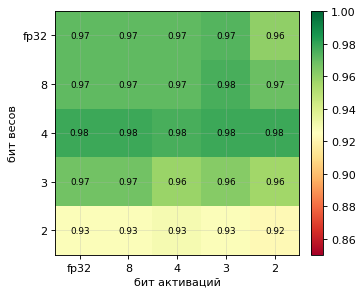

,A=fp32,A=8,A=4,A=3,A=2
W=fp32,0.971,0.971,0.971,0.973,0.960
W=8,0.971,0.971,0.971,0.976,0.969
W=4,0.978,0.978,0.976,0.978,0.978
W=3,0.967,0.967,0.958,0.962,0.956
W=2,0.927,0.927,0.929,0.927,0.922


In [ ]:
opts=[None,8,4,3,2]; lab=["fp32","8","4","3","2"]
G=np.array([[accuracy(base,Xte,yte,act_q=(None if a is None else q_value(a)),w_bits=w)
             for a in opts] for w in opts])
fig,ax=plt.subplots(figsize=(4.6,3.8)); im=ax.imshow(G,cmap="RdYlGn",vmin=0.85,vmax=1.0)
ax.set_xticks(range(5)); ax.set_xticklabels(lab); ax.set_yticks(range(5)); ax.set_yticklabels(lab)
ax.set_xlabel("бит активаций"); ax.set_ylabel("бит весов")
for i in range(5):
    for j in range(5): ax.text(j,i,f"{G[i,j]:.2f}",ha="center",va="center",fontsize=8)
plt.colorbar(im,fraction=0.046,pad=0.04); plt.tight_layout(); plt.show()
pd.DataFrame(G,index=[f"W={l}" for l in lab],columns=[f"A={l}" for l in lab]).style.format("{:.3f}")

Веса и активации квантуются **одним и тем же** равномерным квантователем (при 2 битах — 4 уровня у обоих),
поэтому сравнение честное. При равной битности **веса чувствительнее**: 2-битные активации почти без потерь
(`A=2` ≈ fp32), а 2-битные веса теряют заметно больше (`W=2`). Ответ на вопрос проекта: квантовать активации
и веса — не одно и то же.

## 5. QAT (STE) vs PTQ — честное сравнение

PTQ и QAT стартуют из **одной начальной инициализации** и обучаются **одинаковое число эпох (60)**;
разница только в том, что QAT видит квантователь уже при обучении (градиент по STE).

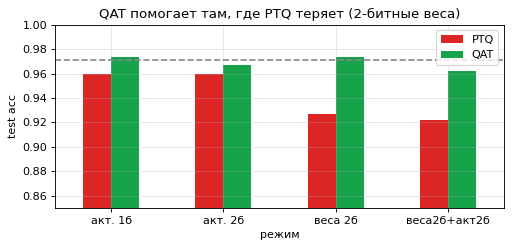

,PTQ,QAT,Δ
режим,,,
акт. 1б,0.960,0.973,0.013
акт. 2б,0.960,0.967,0.007
веса 2б,0.927,0.973,0.047
веса2б+акт2б,0.922,0.962,0.040


In [ ]:
regimes=[("акт. 1б",     dict(act_q=q_value(1))),
         ("акт. 2б",     dict(act_q=q_value(2))),
         ("веса 2б",     dict(w_bits=2)),
         ("веса2б+акт2б",dict(act_q=q_value(2),w_bits=2))]
rows=[]
for nm,kw in regimes:
    ptq=accuracy(base,Xte,yte,**kw)                       # base: та же инициализация, 60 эпох, без квант.
    m=init.clone(); train(m,Xtr,Ytr,ytr,60,**kw)          # QAT: та же инициализация, 60 эпох, с квант.
    qat=accuracy(m,Xte,yte,**kw); rows.append({"режим":nm,"PTQ":ptq,"QAT":qat,"Δ":qat-ptq})
qat_df=pd.DataFrame(rows).set_index("режим")

ax=qat_df[["PTQ","QAT"]].plot(kind="bar",figsize=(6.5,3.2),color=[PAL[1],PAL[2]],rot=0)
ax.axhline(BASE,ls="--",c="#888"); ax.set_ylabel("test acc"); ax.set_ylim(0.85,1.0)
ax.set_title("QAT помогает там, где PTQ теряет (2-битные веса)"); plt.tight_layout(); plt.show()
qat_df.style.format("{:.3f}")

QAT почти не влияет на мягкое квантование активаций (Δ в пределах шума), но восстанавливает
точность при 2-битных весах — там, где PTQ проседает.

## 6. Устойчивость: FGSM, шум, маскировка градиента

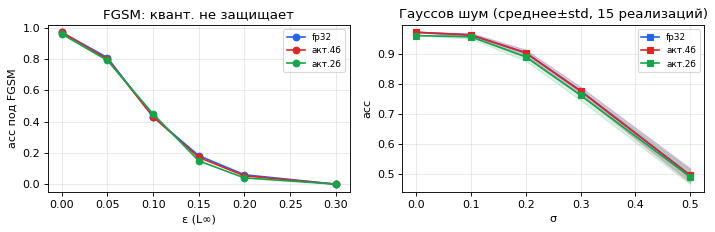

,fp32,акт.4б,акт.2б
ε=0.0,0.971,0.971,0.960
ε=0.05,0.809,0.800,0.791
ε=0.1,0.431,0.431,0.449
ε=0.15,0.182,0.171,0.149
ε=0.2,0.060,0.053,0.040
ε=0.3,0.000,0.000,0.000


In [ ]:
def fgsm(m,X,Y,eps,act_q=None,hd=None):
    return np.clip(X+F32(eps)*np.sign(m.input_grad(X,Y,act_q=act_q,hidden_deriv=hd)),0,1)

eps=[0.0,0.05,0.1,0.15,0.2,0.3]; noise=[0.0,0.1,0.2,0.3,0.5]
S={"fp32":None,"акт.4б":q_value(4),"акт.2б":q_value(2)}
fig,ax=plt.subplots(1,2,figsize=(9,3)); rob={}
for k,(nm,aq) in enumerate(S.items()):
    a=[accuracy(base,fgsm(base,Xte,Yte,e,act_q=aq),yte,act_q=aq) for e in eps]; rob[nm]=a
    ax[0].plot(eps,a,"o-",c=PAL[k],label=nm)
ax[0].set_xlabel("ε (L∞)"); ax[0].set_ylabel("acc под FGSM"); ax[0].set_title("FGSM: квант. не защищает"); ax[0].legend(fontsize=8)

# шум усредняем по 15 реализациям на каждый σ (среднее ± std)
for k,(nm,aq) in enumerate(S.items()):
    mean=[]; std=[]
    for s in noise:
        accs=[accuracy(base,np.clip(Xte+np.random.default_rng(r).normal(0,s,Xte.shape).astype(F32),0,1),yte,act_q=aq)
              for r in range(15)]
        mean.append(np.mean(accs)); std.append(np.std(accs))
    mean=np.array(mean); std=np.array(std)
    ax[1].plot(noise,mean,"s-",c=PAL[k],label=nm); ax[1].fill_between(noise,mean-std,mean+std,color=PAL[k],alpha=0.15)
ax[1].set_xlabel("σ"); ax[1].set_ylabel("acc"); ax[1].set_title("Гауссов шум (среднее±std, 15 реализаций)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rob,index=[f"ε={e}" for e in eps]).style.format("{:.3f}")

**Маскировка градиента.** Кусочно-постоянная LUT имеет истинный наклон ≈0, поэтому «наивная»
атака (градиент через плоскую функцию) проваливается — модель *кажется* устойчивой. STE-атака
(гладкая `f'`) разрушает эту иллюзию.

In [ ]:
lut17=q_lut(17); mrows=[]
for e in [0.05,0.1,0.15,0.2]:
    Xn=fgsm(base,Xte,Yte,e,act_q=lut17,hd=lambda z:np.zeros_like(z))   # наивная (маскировка)
    Xs=fgsm(base,Xte,Yte,e,act_q=lut17,hd=None)                        # STE
    mrows.append({"ε":e,"наивная (маскировка)":accuracy(base,Xn,yte,act_q=lut17),
                  "STE-атака":accuracy(base,Xs,yte,act_q=lut17)})
mask=pd.DataFrame(mrows).set_index("ε"); mask.style.format("{:.3f}")

,наивная (маскировка),STE-атака
ε,,
0.050000,0.973,0.818
0.100000,0.973,0.456
0.150000,0.973,0.182
0.200000,0.973,0.062


## 7. Скорость и память

In [ ]:
# closures создаём ОДИН раз (вне таймера), чтобы не мерить построение таблицы
q_exact=None; q_v4=q_value(4); q_l65=q_lut(65); q_p32=q_pwl(32)
Xb=np.repeat(Xte,20,0)
def bench(aq,r=15):
    base.forward(Xb,act_q=aq)
    t=time.time()
    for _ in range(r): base.forward(Xb,act_q=aq)
    return (time.time()-t)/r*1000
tt={"tanh (точно)":bench(q_exact),"квант.выхода-4":bench(q_v4),"LUT-65узлов":bench(q_l65),"PWL-32":bench(q_p32)}
print("время инференса,",Xb.shape[0],"объектов:", {k:round(v,1) for k,v in tt.items()},"мс")
print("Вывод: в данной NumPy-реализации ускорения не обнаружено; результат зависит от оборудования и среды.")
print("       Экономия — по ПАМЯТИ активаций (линейно по битности); реальное ускорение требует целочисленного железа.")

pd.DataFrame({"бит":[32,8,4,2,1],"память от fp32":["100%","25%","12.5%","6.25%","3.13%"],
   "acc PTQ (квант.выхода)":[BASE]+[accuracy(base,Xte,yte,act_q=q_value(b)) for b in [8,4,2,1]]})\
   .set_index("бит").style.format({"acc PTQ (квант.выхода)":"{:.3f}"})

время инференса, 9000 объектов: {'tanh (точно)': 47.1, 'квант.выхода-4': 99.6, 'LUT-65узлов': 107.5, 'PWL-32': 112.1} мс
Вывод: в данной NumPy-реализации ускорения не обнаружено; результат зависит от оборудования и среды.
       Экономия — по ПАМЯТИ активаций (линейно по битности); реальное ускорение требует целочисленного железа.


,память от fp32,acc PTQ (квант.выхода)
бит,,
32,100%,0.971
8,25%,0.971
4,12.5%,0.971
2,6.25%,0.960
1,3.13%,0.960


## 8. Сводная таблица

In [ ]:
f=lambda a: f"{a:.3f}"
w2a2_ptq=accuracy(base,Xte,yte,act_q=q_value(2),w_bits=2)
pd.DataFrame([
 ["MLP tanh 64-128-64-10 (float32)","—","fp32 (эталон)",f(BASE)],
 ["","PTQ актив. 2б","актив. vs fp32",f"{f(accuracy(base,Xte,yte,act_q=q_value(2)))} / {f(BASE)}"],
 ["","квант. весов 2б","веса vs актив.2б",f"{f(accuracy(base,Xte,yte,w_bits=2))} / {f(accuracy(base,Xte,yte,act_q=q_value(2)))}"],
 ["","QAT при весах+актив.2б","PTQ vs QAT",f"{f(w2a2_ptq)} / {f(qat_df.loc['веса2б+акт2б','QAT'])}"],
 ["","FGSM ε=0.1","fp32 vs актив.2б",f"{f(rob['fp32'][2])} / {f(rob['акт.2б'][2])}"],
 ["","LUT, FGSM ε=0.2","наивная vs STE",f"{f(mask.loc[0.2,'наивная (маскировка)'])} / {f(mask.loc[0.2,'STE-атака'])}"],
],columns=["базовая модель","возмущение/атака","сравнение/защита","точность"]).style.hide(axis="index")

базовая модель,возмущение/атака,сравнение/защита,точность
MLP tanh 64-128-64-10 (float32),—,fp32 (эталон),0.971
,PTQ актив. 2б,актив. vs fp32,0.960 / 0.971
,квант. весов 2б,веса vs актив.2б,0.927 / 0.960
,QAT при весах+актив.2б,PTQ vs QAT,0.922 / 0.962
,FGSM ε=0.1,fp32 vs актив.2б,0.431 / 0.449
,"LUT, FGSM ε=0.2",наивная vs STE,0.973 / 0.062


## 9. Выводы

- **Квантование активаций дёшево.** У насыщающейся `tanh` значения скапливаются у $\pm1$, поэтому
  даже 1–2 бита теряют ~1% точности; при 3–8 битах разница с fp32 в пределах шума теста, а монотонный
  эффект виден по расхождению логитов. При 1 бите запас логитов даже растёт (огрубление повышает «уверенность»).
- **Веса чувствительнее активаций.** При честном сравнении (одинаковый 4-уровневый квантователь, 2 бита)
  2-битные активации почти без потерь, а 2-битные веса теряют заметно больше. Ответ на вопрос проекта:
  квантовать активации и веса — не одно и то же.
- **QAT** не нужен для мягкого квантования активаций, но восстанавливает точность при 2-битных весах
  (общая инициализация, равное число эпох — сравнение честное).
- **Устойчивость.** Квантование активаций **не защищает** от FGSM (STE-атака проходит насквозь).
  Кусочно-постоянная LUT даёт **ложную устойчивость** (маскировка градиента), ломаемую STE-атакой.
- **Память/скорость.** Экономия памяти линейна по битности; в данной NumPy-реализации ускорения
  не обнаружено — оно зависит от среды и требует целочисленного железа.

*Ограничения:* датасет `digits` 8×8 мал; одна атака (FGSM) — PGD дал бы более жёсткую оценку;
активация только `tanh`; шум усреднён по 15 реализациям, атаки — по одному прогону. Это отмечено
как направления усиления до портфельного варианта.

,tanh,relu
1 бит,0.960,0.853
2 бит,0.967,0.964
3 бит,0.978,0.971
4 бит,0.980,0.976
6 бит,0.982,0.978
8 бит,0.982,0.978
fp32,0.982,0.982


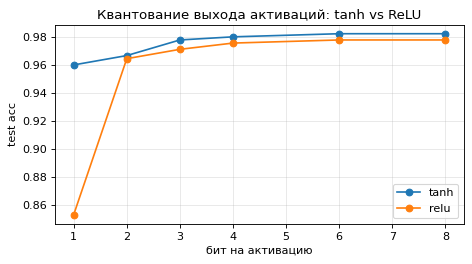

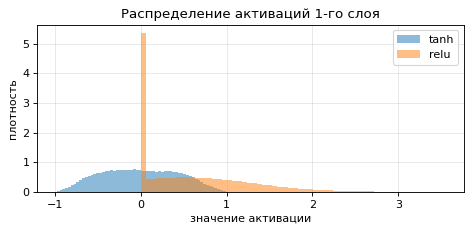

In [ ]:
# ================== ReLU vs tanh под квантованием активаций (P14) ==================
# Идея: tanh ограничен (-1,1) -> квантование выхода дёшево; ReLU не ограничен ->
# нужен калиброванный диапазон, и при малой битности он чувствительнее.
# Переопределяем активации, добавляя ReLU (QMLP.forward/loss_grad берут эти глобальные функции).
def act_forward(name, x):
    if name == "tanh": return np.tanh(x)
    if name == "relu": return np.maximum(0, x)
def act_deriv(name, x):
    if name == "tanh": t = np.tanh(x); return 1 - t*t
    if name == "relu": return (x > 0).astype(x.dtype)

# две модели из одинакового протокола обучения (tanh: инициализация Xavier, relu: He — уже в QMLP)
models = {"tanh": train(QMLP([64,128,64,10], "tanh"), Xtr, Ytr, ytr, 60),
          "relu": train(QMLP([64,128,64,10], "relu"), Xtr, Ytr, ytr, 60)}

# диапазон для квантования выхода: у tanh фиксирован (-1,1); у ReLU калибруем верх по train
def act_range_of(m, act):
    if act == "tanh": return (-1.0, 1.0)
    z1 = Xtr @ m.W[0] + m.b[0]                       # активации 1-го слоя до ReLU
    return (0.0, float(np.percentile(np.maximum(0, z1), 99.9)))   # 99.9-й перцентиль = clip

q_out = lambda lo, hi, bits: (lambda z, ex: quant_uniform_value(ex, lo, hi, bits))

# развёртка точности по битности (один калиброванный диапазон на все скрытые слои — упрощение)
bits = [1, 2, 3, 4, 6, 8]; res = {}
for act, m in models.items():
    lo, hi = act_range_of(m, act)
    res[act] = [accuracy(m, Xte, yte, act_q=q_out(lo, hi, b)) for b in bits]

tbl = pd.DataFrame(res, index=[f"{b} бит" for b in bits])
tbl.loc["fp32"] = {a: accuracy(m, Xte, yte) for a, m in models.items()}
display(tbl.round(3))

# график 1: точность vs бит активаций
plt.figure(figsize=(6, 3.4))
for act in models:
    plt.plot(bits, res[act], "o-", label=act)
plt.xlabel("бит на активацию"); plt.ylabel("test acc")
plt.title("Квантование выхода активаций: tanh vs ReLU"); plt.legend(); plt.tight_layout(); plt.show()

# график 2: распределение активаций 1-го слоя — объясняет разницу
plt.figure(figsize=(6, 3))
for act, m in models.items():
    a1 = act_forward(act, Xtr @ m.W[0] + m.b[0]).ravel()
    plt.hist(a1, bins=60, density=True, alpha=0.5, label=act)
plt.xlabel("значение активации"); plt.ylabel("плотность")
plt.title("Распределение активаций 1-го слоя"); plt.legend(); plt.tight_layout(); plt.show()